In [20]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("Python executable:", sys.executable)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

print("Environment setup successful!")

Python executable: a:\Crop-Disease-Detection\venv\Scripts\python.exe
NumPy version: 2.5.5
Pandas version: 3.1.1
Environment setup successful!


In [21]:
import os 
import pandas as pd
from pathlib import Path


In [22]:
# Dataset location 
DATASET_DIR=Path("../dataset/raw/Plant Village Dataset")

#DATASET Folders
splits=["Train","Val","Test"]

# Supported image formats
image_extensions= {".jpg",".jpeg",".png",".bmp"}

# Store results
data=[]

for split in splits:
    split_path =DATASET_DIR/split
    print(f"\nChecking {split} dataset....")

    for class_folder in split_path.iterdir():
        if class_folder.is_dir():
            images =[
                file for file in class_folder.iterdir()
                if file.is_file()
                and file.suffix.lower() in image_extensions
            ]

            count =len(images)

            data.append({
                "Dataset" : split,
                "Class": class_folder.name,
                "Image_Count":count
            })
            print(f'{class_folder.name}: {count} images')

# Convert results into a DataFrame
df =pd.DataFrame(data)

print("\nDataset exploration completed!")



Checking Train dataset....
Apple - Apple Scab: 2016 images
Apple - Black Rot: 1987 images
Apple - Cedar Apple Rust: 1760 images
Apple - Healthy: 2008 images
Bell Pepper - Bacterial Spot: 1913 images
Bell Pepper - Healthy: 1988 images
Cherry - Healthy: 1826 images
Cherry - Powdery Mildew: 1683 images
Corn (Maize) - Cercospora Leaf Spot: 1642 images
Corn (Maize) - Common Rust: 1907 images
Corn (Maize) - Healthy: 1859 images
Corn (Maize) - Northern Leaf Blight: 1908 images
Grape - Black Rot: 1888 images
Grape - Esca (Black Measles): 1920 images
Grape - Healthy: 1692 images
Grape - Leaf Blight: 1722 images
Peach - Bacterial Spot: 1838 images
Peach - Healthy: 1728 images
Potato - Early Blight: 1939 images
Potato - Healthy: 1824 images
Potato - Late Blight: 1939 images
Strawberry - Healthy: 1824 images
Strawberry - Leaf Scorch: 1774 images
Tomato - Bacterial Spot: 1702 images
Tomato - Early Blight: 1920 images
Tomato - Healthy: 1926 images
Tomato - Late Blight: 1851 images
Tomato - Septoria

In [23]:
df

,Dataset,Class,Image_Count
0,Train,Apple - Apple Scab,2016
1,Train,Apple - Black Rot,1987
2,Train,Apple - Cedar Apple Rust,1760
3,Train,Apple - Healthy,2008
4,Train,Bell Pepper - Bacterial Spot,1913
...,...,...,...
82,Test,Tomato - Early Blight,48
83,Test,Tomato - Healthy,49
84,Test,Tomato - Late Blight,47
85,Test,Tomato - Septoria Leaf Spot,44


In [24]:
# Total images in each split
print(df.groupby("Dataset")["Image_Count"].sum())

# Total number of images
print("\nTotal images:",df["Image_Count"].sum())

# Total number of disease classes
print("Total Classes:",df["Class"].nunique())

Dataset
Test      1354
Train    53690
Val      12067
Name: Image_Count, dtype: int64

Total images: 67111
Total Classes: 29


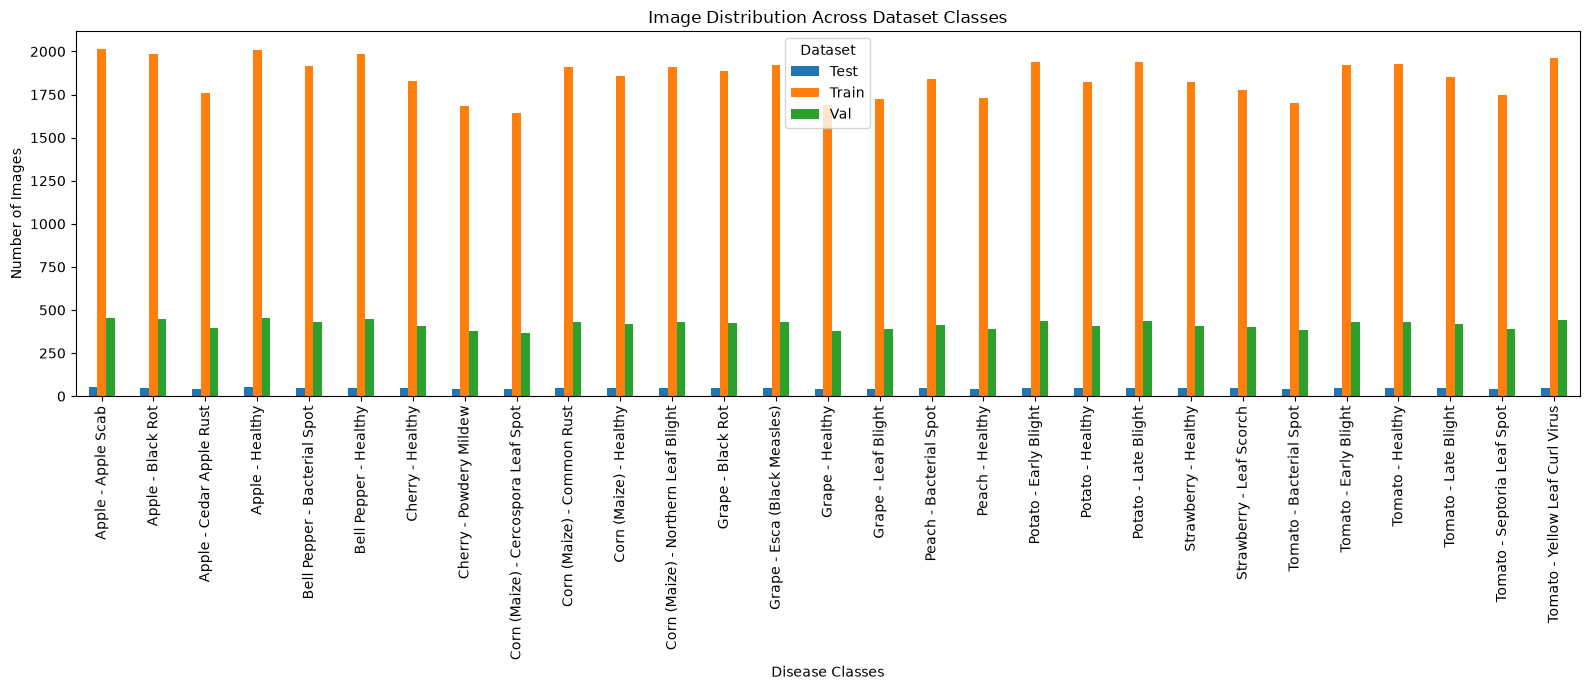

In [25]:
import matplotlib.pyplot as plt

#Group images by class and datasets 
pivot_df = df.pivot(
    index="Class",
    columns="Dataset",
    values="Image_Count"
).fillna(0)

#Plot
pivot_df.plot(
    kind="bar",
    figsize=(16,7)
)

plt.title("Image Distribution Across Dataset Classes")
plt.xlabel("Disease Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=90)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

In [26]:
# Check whether all three folders have the same classes 

class_sets={}

for split in splits:
    split_path= DATASET_DIR/split

    class_sets[split]={
        folder.name
        for folder in split_path.iterdir()
        if folder.is_dir()
    }

#Compare classes
print("Train vs Val:",class_sets["Train"]==class_sets["Val"])
print("Train vs Test:", class_sets["Train"]==class_sets["Test"])

# Finding missing classes 
for split in ["Val","Test"]:

    missing = class_sets["Train"] - class_sets[split]
    print(f"\n Classes missing in {split}: ")

    if missing:
        print(missing)
    else:
        print("None")


Train vs Val: True
Train vs Test: True

 Classes missing in Val: 
None

 Classes missing in Test: 
None


In [27]:
# Save class-wise image counts

df.to_csv(
    "../dataset/image_counts.csv",
    index=False
)

print("Dataset statistics saved successfully!")


Dataset statistics saved successfully!
